# Heart Disease Classification using K-Nearest Neighbors (KNN)
### Introduction to Data Mining — Final Project

**Dataset:** UCI Heart Disease Dataset (Processed Cleveland Data)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

This notebook walks through a complete data mining pipeline on the processed Cleveland
heart disease dataset: inspecting and cleaning the raw data, exploring it visually,
preparing features for a distance-based classifier, and training/evaluating a
K-Nearest Neighbors (KNN) model to predict the presence of heart disease.


## 1. Introduction & Objective

Coronary heart disease is diagnosed using a mix of clinical measurements (blood
pressure, cholesterol, ECG results, etc.). The goal of this project is to build a
**binary classifier** that predicts whether a patient has heart disease based on
14 clinical attributes, using the **K-Nearest Neighbors (KNN)** algorithm.

**Project steps:**
1. Load and inspect the raw dataset
2. Clean the data (handle missing values)
3. Explore the data visually (EDA)
4. Normalize the features
5. Split the data into training and test sets
6. Train a KNN classifier
7. Test different values of K to find the best one
8. Evaluate the final model using accuracy, precision, recall, F1-score, and a confusion matrix
9. Draw conclusions


In [1]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 2. Loading the Data

The raw file `processed.cleveland.data` has **no header row** and uses `?` for
missing values. We assign the 14 official column names documented in
`heart-disease.names`:

| # | Column | Meaning |
|---|--------|---------|
| 1 | age | age in years |
| 2 | sex | 1 = male, 0 = female |
| 3 | cp | chest pain type (1-4) |
| 4 | trestbps | resting blood pressure (mm Hg) |
| 5 | chol | serum cholesterol (mg/dl) |
| 6 | fbs | fasting blood sugar > 120 mg/dl (1 = true) |
| 7 | restecg | resting electrocardiographic results (0-2) |
| 8 | thalach | maximum heart rate achieved |
| 9 | exang | exercise induced angina (1 = yes) |
| 10 | oldpeak | ST depression induced by exercise relative to rest |
| 11 | slope | slope of the peak exercise ST segment (1-3) |
| 12 | ca | number of major vessels (0-3) colored by flourosopy |
| 13 | thal | 3 = normal, 6 = fixed defect, 7 = reversable defect |
| 14 | num | diagnosis (0 = no disease, 1-4 = increasing severity) — **target** |


In [2]:
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'
]

df = pd.read_csv(
    "../data/processed.cleveland.data",
    header=None,
    names=column_names,
    na_values="?"
)

print("Shape:", df.shape)
df.head(10)


Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
df.describe()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


## 3. Data Cleaning

### 3.1 Checking for missing values

The dataset uses `?` for unknown values, which we already converted to `NaN` with
`na_values="?"` when loading. Let's see how many are missing and where.


In [5]:
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0])
print()
print(f"Total rows with at least one missing value: {df.isna().any(axis=1).sum()} "
      f"out of {len(df)} ({df.isna().any(axis=1).mean()*100:.1f}%)")


Missing values per column:
ca      4
thal    2
dtype: int64

Total rows with at least one missing value: 6 out of 303 (2.0%)


In [6]:
df[df.isna().any(axis=1)]


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


### 3.2 Handling missing values

Only the `ca` (number of major vessels) and `thal` (thalassemia test result)
columns contain missing values, and only **6 rows out of 303** (about 2%) are
affected. Because this fraction is so small, dropping these rows is safe and
avoids introducing artificial values into a medical dataset — we won't invent
data for attributes we don't actually know.


In [7]:
df_clean = df.dropna().reset_index(drop=True)
print("Shape before cleaning:", df.shape)
print("Shape after cleaning: ", df_clean.shape)


Shape before cleaning: (303, 14)
Shape after cleaning:  (297, 14)


### 3.3 Defining the classification target

The original `num` column is **multi-class** (0 = no disease, 1-4 = increasing
severity of disease). Following the standard approach used in nearly all
published work on this dataset (see `heart-disease.names`), we convert this into
a **binary target**:

- `0` → no heart disease (`num == 0`)
- `1` → presence of heart disease (`num >= 1`)


In [8]:
df_clean['target'] = (df_clean['num'] > 0).astype(int)
df_clean = df_clean.drop(columns=['num'])

print(df_clean['target'].value_counts())
print()
print(df_clean['target'].value_counts(normalize=True).round(3))


target
0    160
1    137
Name: count, dtype: int64

target
0    0.539
1    0.461
Name: proportion, dtype: float64


In [9]:
df_clean.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target class balance


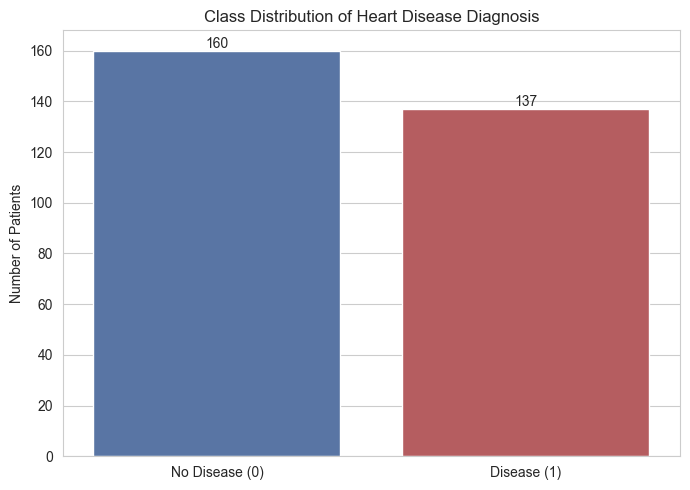

In [10]:
ax = sns.countplot(x='target', hue='target', data=df_clean,
                    palette=['#4C72B0', '#C44E52'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Disease (0)', 'Disease (1)'])
ax.set_title('Class Distribution of Heart Disease Diagnosis')
ax.set_xlabel('')
ax.set_ylabel('Number of Patients')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.savefig('../outputs/figures/target_distribution.png', dpi=150)
plt.show()


### 4.2 Age distribution by diagnosis

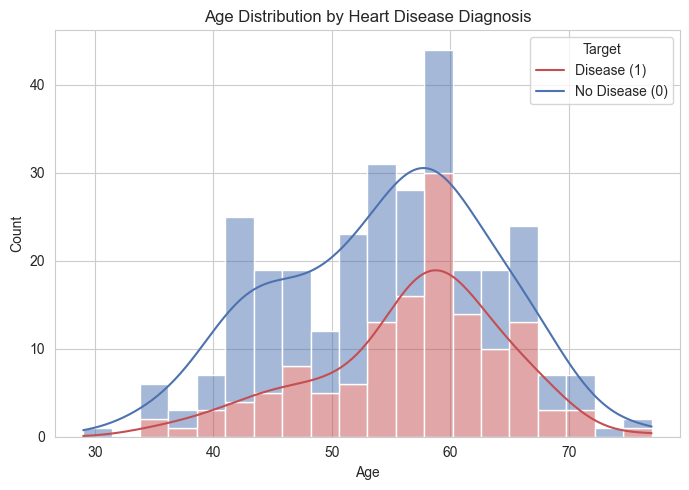

In [11]:
plt.figure(figsize=(7,5))
sns.histplot(data=df_clean, x='age', hue='target', bins=20, kde=True,
             palette=['#4C72B0', '#C44E52'], multiple='stack')
plt.title('Age Distribution by Heart Disease Diagnosis')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(title='Target', labels=['Disease (1)', 'No Disease (0)'])
plt.tight_layout()
plt.savefig('../outputs/figures/age_distribution.png', dpi=150)
plt.show()


### 4.3 Sex vs. diagnosis

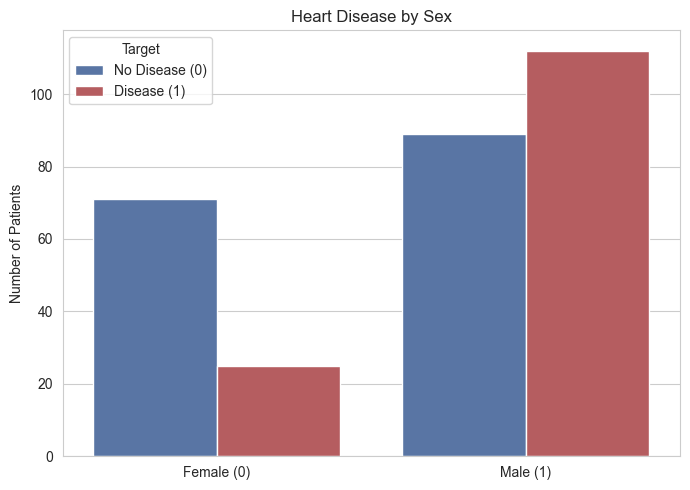

In [12]:
ax = sns.countplot(x='sex', hue='target', data=df_clean, palette=['#4C72B0', '#C44E52'])
ax.set_xticks([0, 1])
ax.set_xticklabels(['Female (0)', 'Male (1)'])
ax.set_title('Heart Disease by Sex')
ax.set_xlabel('')
ax.set_ylabel('Number of Patients')
plt.legend(title='Target', labels=['No Disease (0)', 'Disease (1)'])
plt.tight_layout()
plt.savefig('../outputs/figures/sex_vs_target.png', dpi=150)
plt.show()


### 4.4 Key numeric features by diagnosis

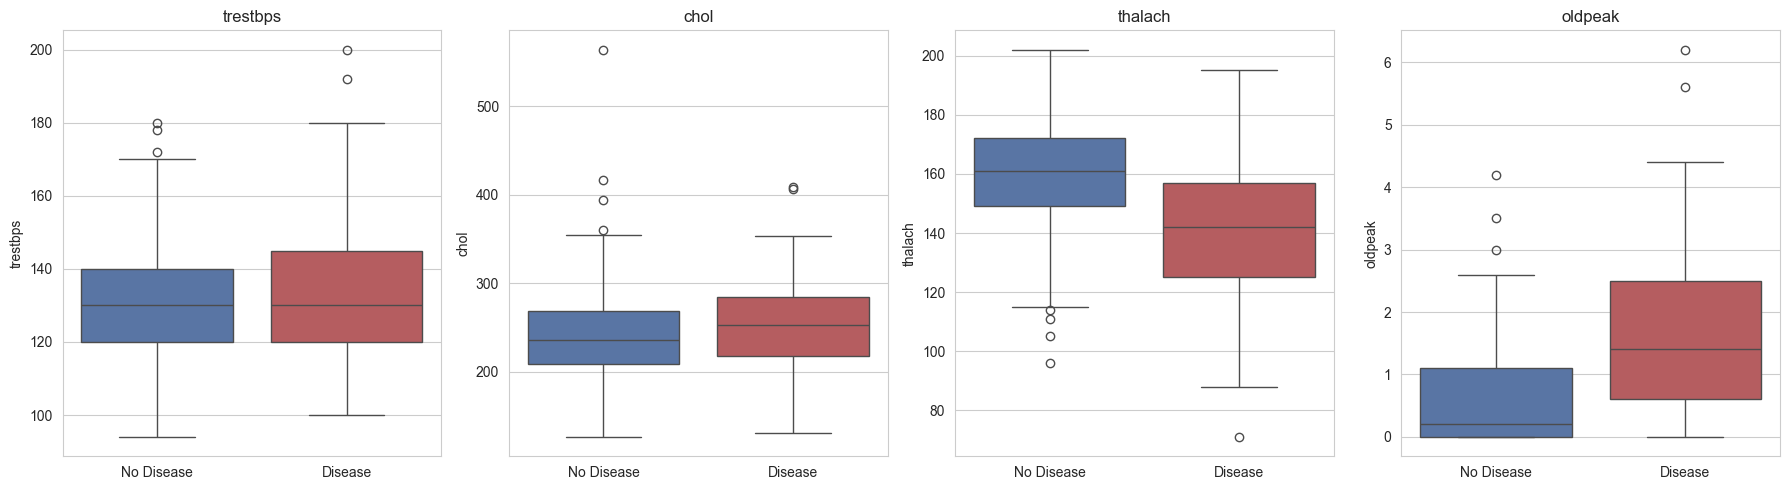

In [13]:
numeric_features = ['trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, feat in zip(axes, numeric_features):
    sns.boxplot(x='target', y=feat, hue='target', data=df_clean, ax=ax,
                palette=['#4C72B0', '#C44E52'], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No Disease', 'Disease'])
    ax.set_title(feat)
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig('../outputs/figures/boxplots_numeric.png', dpi=150)
plt.show()


### 4.5 Correlation heatmap

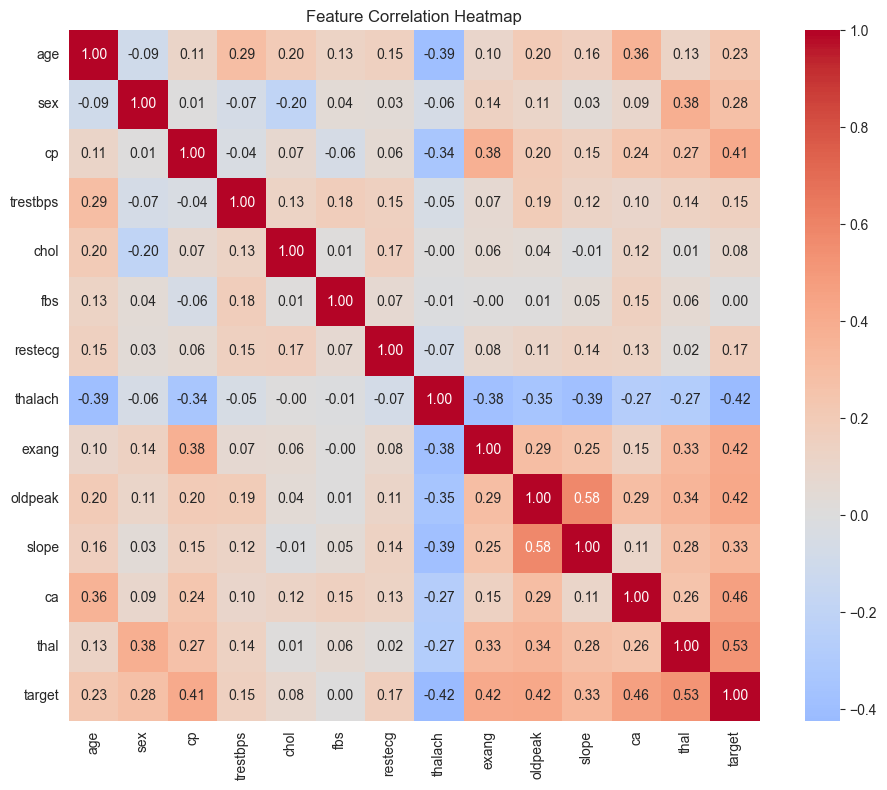

In [14]:
plt.figure(figsize=(10, 8))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('../outputs/figures/correlation_heatmap.png', dpi=150)
plt.show()


In [15]:
print("Correlation of each feature with the target:")
print(corr['target'].drop('target').sort_values(key=abs, ascending=False))


Correlation of each feature with the target:
thal        0.526640
ca          0.463189
oldpeak     0.424052
thalach    -0.423817
exang       0.421355
cp          0.408945
slope       0.333049
sex         0.278467
age         0.227075
restecg     0.166343
trestbps    0.153490
chol        0.080285
fbs         0.003167
Name: target, dtype: float64


## 5. Train/Test Split

We split the data **before** scaling to avoid *data leakage* — the scaler must
only ever "see" the training data's statistics. We use `stratify=y` so both the
training and test sets keep the same proportion of disease/no-disease cases as
the full dataset.


In [16]:
X = df_clean.drop(columns=['target'])
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training set size:", X_train.shape)
print("Test set size:    ", X_test.shape)
print()
print("Training target distribution:\n", y_train.value_counts(normalize=True).round(3))
print()
print("Test target distribution:\n", y_test.value_counts(normalize=True).round(3))


Training set size: (237, 13)
Test set size:     (60, 13)

Training target distribution:
 target
0    0.54
1    0.46
Name: proportion, dtype: float64

Test target distribution:
 target
0    0.533
1    0.467
Name: proportion, dtype: float64


## 6. Feature Normalization

KNN is a **distance-based** algorithm: it classifies a new point based on the
majority class among its nearest neighbors, measured with Euclidean distance.
If features are on very different scales (e.g. `chol` is in the hundreds while
`oldpeak` is between 0 and 6), features with larger numeric ranges would
dominate the distance calculation. We use `StandardScaler` to rescale every
feature to mean 0 and standard deviation 1.

The scaler is **fit only on the training data**, then used to transform both
the training and test sets.


In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled training features (should be ~0):")
print(np.round(X_train_scaled.mean(axis=0), 3))
print()
print("Std of scaled training features (should be ~1):")
print(np.round(X_train_scaled.std(axis=0), 3))


Mean of scaled training features (should be ~0):
[-0.  0.  0. -0. -0. -0.  0. -0.  0.  0.  0.  0. -0.]

Std of scaled training features (should be ~1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 7. KNN Classification — Baseline Model

We start with a baseline KNN model using `k=5` neighbors (a common default).


In [18]:
knn_baseline = KNeighborsClassifier(n_neighbors=5)
knn_baseline.fit(X_train_scaled, y_train)

y_pred_baseline = knn_baseline.predict(X_test_scaled)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print(f"Baseline KNN (k=5) test accuracy: {baseline_accuracy:.4f}")


Baseline KNN (k=5) test accuracy: 0.8833


## 8. Testing Different K Values

The choice of `k` affects model performance: a very small `k` can overfit to
noise, while a very large `k` can oversmooth the decision boundary. We test
`k` from 1 to 30 and track test accuracy for each.


In [19]:
k_values = range(1, 31)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, pred))

results_df = pd.DataFrame({'k': list(k_values), 'accuracy': accuracies})
best_row = results_df.loc[results_df['accuracy'].idxmax()]
best_k = int(best_row['k'])

print(results_df)
print()
print(f"Best k = {best_k} with test accuracy = {best_row['accuracy']:.4f}")


     k  accuracy
0    1  0.783333
1    2  0.816667
2    3  0.900000
3    4  0.850000
4    5  0.883333
5    6  0.850000
6    7  0.833333
7    8  0.850000
8    9  0.866667
9   10  0.883333
10  11  0.883333
11  12  0.883333
12  13  0.866667
13  14  0.866667
14  15  0.850000
15  16  0.850000
16  17  0.850000
17  18  0.816667
18  19  0.866667
19  20  0.850000
20  21  0.850000
21  22  0.850000
22  23  0.866667
23  24  0.866667
24  25  0.866667
25  26  0.866667
26  27  0.866667
27  28  0.866667
28  29  0.866667
29  30  0.866667



Best k = 3 with test accuracy = 0.9000


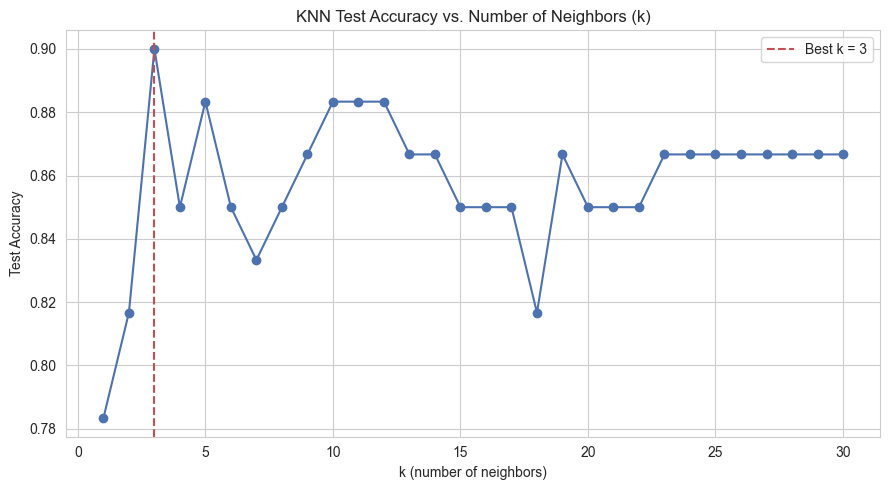

In [20]:
plt.figure(figsize=(9, 5))
plt.plot(results_df['k'], results_df['accuracy'], marker='o', color='#4C72B0')
plt.axvline(best_k, color='#C44E52', linestyle='--', label=f'Best k = {best_k}')
plt.title('KNN Test Accuracy vs. Number of Neighbors (k)')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Test Accuracy')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/accuracy_vs_k.png', dpi=150)
plt.show()


## 9. Final Model Evaluation

We train the final KNN model using the best `k` found above and evaluate it
with multiple metrics: **accuracy**, **precision**, **recall**, **F1-score**,
and a **confusion matrix**.


In [21]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
y_pred_final = final_knn.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred_final)
prec = precision_score(y_test, y_pred_final)
rec = recall_score(y_test, y_pred_final)
f1 = f1_score(y_test, y_pred_final)

print(f"Final KNN model (k={best_k})")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print()
print("Full classification report:")
print(classification_report(y_test, y_pred_final, target_names=['No Disease', 'Disease']))


Final KNN model (k=3)
Accuracy:  0.9000
Precision: 0.8929
Recall:    0.8929
F1-score:  0.8929

Full classification report:
              precision    recall  f1-score   support

  No Disease       0.91      0.91      0.91        32
     Disease       0.89      0.89      0.89        28

    accuracy                           0.90        60
   macro avg       0.90      0.90      0.90        60
weighted avg       0.90      0.90      0.90        60



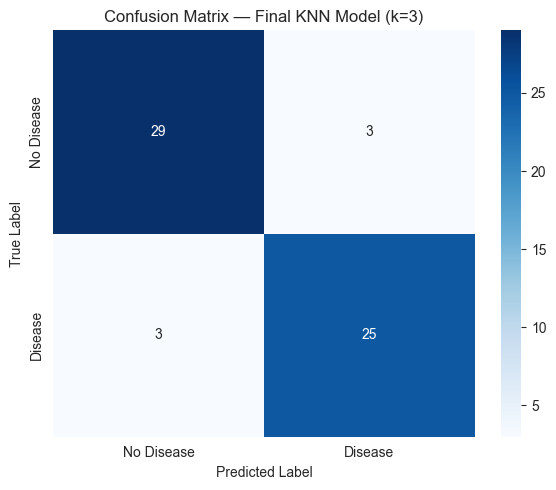

In [22]:
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.title(f'Confusion Matrix — Final KNN Model (k={best_k})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('../outputs/figures/confusion_matrix.png', dpi=150)
plt.show()


## 10. Conclusion

**Data.** The processed Cleveland dataset originally contained 303 patients and
14 attributes. Only 6 rows (2.0%) had missing values (in `ca` and `thal`), so
these were dropped, leaving **297 complete records**. The multi-class `num`
target was converted into a binary label: **160 patients (53.9%) with no
heart disease** and **137 patients (46.1%) with heart disease** — a fairly
balanced dataset, which is why plain accuracy is a reasonable metric here.

**EDA.** The correlation analysis showed that `thal` (0.53), `ca` (0.46),
`oldpeak` (0.42), `thalach` (-0.42), `exang` (0.42), and `cp` (0.41) have the
strongest linear association with the presence of heart disease, while `fbs`
(0.003) and `chol` (0.08) are nearly uninformative on their own. The boxplots
confirmed this: patients with heart disease tend to have a lower maximum heart
rate (`thalach`) and a higher ST depression (`oldpeak`) than patients without
disease.

**Modeling.** After scaling all 13 features with `StandardScaler` and
splitting the data 80/20 (stratified, 237 train / 60 test), we tested KNN with
`k` from 1 to 30. Accuracy ranged from 78.3% (k=1) to a peak of **90.0% at
k=3**, after which it fluctuated between 82–89% for larger k. Very small `k`
(especially k=1) overfits to individual training points, while the accuracy
curve flattens out for k ≥ 9, showing diminishing returns from averaging over
more neighbors on this dataset size.

**Final model (k=3) performance on the test set:**

| Metric | Value |
|---|---|
| Accuracy | 0.900 |
| Precision | 0.893 |
| Recall | 0.893 |
| F1-score | 0.893 |

The confusion matrix was:

|  | Predicted: No Disease | Predicted: Disease |
|---|---|---|
| **Actual: No Disease** | 29 (TN) | 3 (FP) |
| **Actual: Disease** | 3 (FN) | 25 (TP) |

Out of 60 test patients, the model misclassified only 6 (3 false positives and
3 false negatives) — an equal trade-off between the two error types, with no
strong bias toward over- or under-predicting disease.

**Limitations.**
- The dataset is small (297 patients after cleaning), so the test set (60
  patients) is small too — a single train/test split can be somewhat sensitive
  to which patients land in the test set. k-fold cross-validation would give a
  more robust estimate of generalization performance.
- The original 5-level severity label (`num` 0–4) was collapsed into a binary
  "disease / no disease" label, which is standard practice for this dataset
  but discards information about disease severity.
- KNN has no built-in way to tell us *which* features drove an individual
  prediction (unlike, say, a decision tree), which matters in a medical
  context where interpretability is important.

**Overall**, a simple KNN classifier with k=3 achieves 90% accuracy at
distinguishing the presence vs. absence of heart disease on this dataset,
showing that even a basic distance-based model can perform well once the
features are properly cleaned and normalized.
